In [24]:
import numpy as np
import matplotlib.pyplot as plt
import os 

In [25]:
data_map = {"synthetic": "Synthetic",
            "fashion_mnist": "Fashion MNIST"}

In [26]:
# Dataset 
dataset = "fashion_mnist"
N = 60000
N_val = 10000
d = 784
K = 10

# Network
act = "SiLU"
L = 4
init = "orthogonal"
init_scale = 1e-1
lr1 = 1e-5
lr2 = lr1
comp_sub = 2

num_full_params = "1.85M"
num_comp_params = "40.4K"


data_dir = dataset + '_d_' + str(d) + '_K_' + str(K) + '_N_' + str(N)
orig_net_dir = act + '_network_L_' + str(L) + '_' + init + '_init_scale_' + str(init_scale) + '_eta_' + str(lr1)
orig_load_dir = os.path.join('./results', data_dir, orig_net_dir)

comp_net_dir = orig_net_dir = act + '_network_L_' + str(L) + '_' + init + '_init_scale_' + str(init_scale) + '_eta_' + str(lr2)
comp_load_dir = os.path.join('./results', data_dir, comp_net_dir)

In [27]:
# Original model
orig_losses = np.load(os.path.join(orig_load_dir, 'orig_model_losses.npz'))
orig_accs = np.load(os.path.join(orig_load_dir, 'orig_model_accs.npz'))

orig_train_losses = orig_losses['train_losses'] / N
orig_val_losses = orig_losses['val_losses'] / N_val

orig_train_accs = orig_accs['train_accs']
orig_val_accs = orig_accs['val_accs']

# Compressed model
comp_losses = np.load(os.path.join(comp_load_dir, 'compressed_model_subspace_' + str(comp_sub) + '_losses.npz'))
comp_accs = np.load(os.path.join(comp_load_dir, 'compressed_model_subspace_' + str(comp_sub) + '_accs.npz'))

comp_train_losses = comp_losses['train_losses'] / N
comp_val_losses = comp_losses['val_losses'] / N_val

comp_train_accs = comp_accs['train_accs']
comp_val_accs = comp_accs['val_accs']

# Compressed model with random subspace
comp_rand_losses = np.load(os.path.join(comp_load_dir, 'compressed_model_subspace_None_losses.npz'))
comp_rand_accs = np.load(os.path.join(comp_load_dir, 'compressed_model_subspace_None_accs.npz'))

comp_rand_train_losses = comp_rand_losses['train_losses'] / N
comp_rand_val_losses = comp_rand_losses['val_losses'] / N_val

comp_rand_train_accs = comp_rand_accs['train_accs']
comp_rand_val_accs = comp_rand_accs['val_accs']


epochs = orig_train_losses.shape[1]

In [28]:
# Original model
mean_orig_train_losses = np.mean(orig_train_losses, axis=0)
std_orig_train_losses = np.std(orig_train_losses, axis=0)

mean_orig_val_losses = np.mean(orig_val_losses, axis=0)
std_orig_val_losses = np.std(orig_val_losses, axis=0)


mean_orig_train_accs = np.mean(orig_train_accs, axis=0)
std_orig_train_accs = np.std(orig_train_accs, axis=0)

mean_orig_val_accs = np.mean(orig_val_accs, axis=0)
std_orig_val_accs = np.std(orig_val_accs, axis=0)

max_orig_val_accs = np.max(orig_val_accs, axis=1)
std_max_orig_val_accs = np.std(max_orig_val_accs)


# Compressed model
mean_comp_train_losses = np.mean(comp_train_losses, axis=0)
std_comp_train_losses = np.std(comp_train_losses, axis=0)

mean_comp_val_losses = np.mean(comp_val_losses, axis=0)
std_comp_val_losses = np.std(comp_val_losses, axis=0)


mean_comp_train_accs = np.mean(comp_train_accs, axis=0)
std_comp_train_accs = np.std(comp_train_accs, axis=0)

mean_comp_val_accs = np.mean(comp_val_accs, axis=0)
std_comp_val_accs = np.std(comp_val_accs, axis=0)


max_comp_val_accs = np.max(comp_val_accs, axis=1)
std_max_comp_val_accs = np.std(max_comp_val_accs)


# Compressed model with random subspace initialization
mean_comp_rand_train_losses = np.mean(comp_rand_train_losses, axis=0)
std_comp_rand_train_losses = np.std(comp_rand_train_losses, axis=0)

mean_comp_rand_val_losses = np.mean(comp_rand_val_losses, axis=0)
std_comp_rand_val_losses = np.std(comp_rand_val_losses, axis=0)


mean_comp_rand_train_accs = np.mean(comp_rand_train_accs, axis=0)
std_comp_rand_train_accs = np.std(comp_rand_train_accs, axis=0)

mean_comp_rand_val_accs = np.mean(comp_rand_val_accs, axis=0)
std_comp_rand_val_accs = np.std(comp_rand_val_accs, axis=0)


max_comp_rand_val_accs = np.max(comp_rand_val_accs, axis=1)
std_max_comp_rand_val_accs = np.std(max_comp_rand_val_accs)


print("Best orig. model val accuracy = (", np.mean(max_orig_val_accs), ", ", std_max_orig_val_accs, ")")
print("Best compressed (S perp init.) model val accuracy = (", np.mean(max_comp_val_accs), ", ", std_max_comp_val_accs, ")")
print("Best compressed (random subspace init.) model val accuracy = (", np.mean(max_comp_rand_val_accs), ", ", std_max_comp_rand_val_accs, ")")

Best orig. model val accuracy = ( 85.26599999999999 ,  0.14974645237868076 )
Best compressed (S perp init.) model val accuracy = ( 84.062 ,  0.7794202974005743 )
Best compressed (random subspace init.) model val accuracy = ( 33.358 ,  6.22151878563426 )


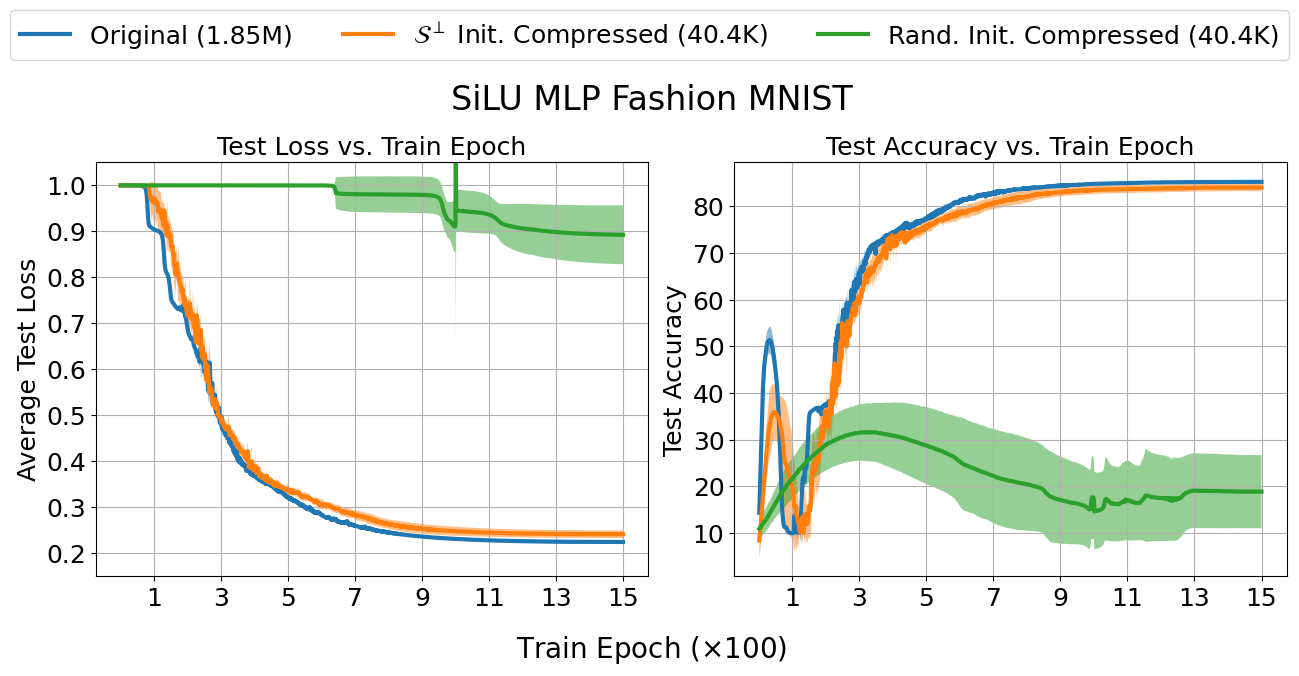

In [29]:
lw = 3

savefig = False

save_net_dir = act + '_network_L_' + str(L) + '_' + init + '_init_scale_' + str(init_scale)
save_dir = os.path.join('./figs', data_dir, save_net_dir)
if savefig and not os.path.exists(save_dir):
    os.makedirs(save_dir)

sci_str = f"{lr1:e}"  # Formats as '1-05'
parts = sci_str.split('e')
scale1 = int(float(parts[0]))
exponent1 = int(parts[1])
lr1_str = f"10^{{{exponent1}}}"


sci_str = f"{lr2:e}"  # Formats as '1-05'
parts = sci_str.split('e')
scale2 = int(float(parts[0]))
exponent2 = int(parts[1])
lr2_str = f"10^{{{exponent2}}}"


# Validation loss
fig = plt.figure(figsize=(13, 6))

ax1 = fig.add_subplot(121)

ax1.plot(np.arange(1, epochs + 1), mean_orig_val_losses, label=r'Original (' + num_full_params + ')', linewidth=lw)
ax1.fill_between(np.arange(1, epochs + 1), mean_orig_val_losses - std_orig_val_losses, mean_orig_val_losses + std_orig_val_losses, alpha=0.5, linewidth=lw)

ax1.plot(np.arange(1, epochs + 1), mean_comp_val_losses, label=r'$\mathcal{S}^\perp$ Init. Compressed (' + num_comp_params + ')', linewidth=lw)
ax1.fill_between(np.arange(1, epochs + 1), mean_comp_val_losses - std_comp_val_losses, mean_comp_val_losses + std_comp_val_losses, alpha=0.5, linewidth=lw)

ax1.plot(np.arange(1, epochs + 1), mean_comp_rand_val_losses, label=r'Rand. Init. Compressed (' + num_comp_params + ')', linewidth=lw)
ax1.fill_between(np.arange(1, epochs + 1), mean_comp_rand_val_losses - std_comp_rand_val_losses, mean_comp_rand_val_losses + std_comp_rand_val_losses, alpha=0.5, linewidth=lw)


#plt.xlabel(r'Train Epoch ($\times 100$)', fontsize=15)
ax1.set_ylabel('Average Test Loss', fontsize=18)

xticks = np.linspace(100, epochs, (epochs // 200) + 1)
xticklabels = np.linspace(1, epochs // 100, (epochs // 200) + 1, dtype=int)

yticks = np.linspace(0.2, 1, 9)
yticks = np.array([ float('%.1f'%(num)) for num in yticks ])

ax1.set_xticks(xticks, labels=xticklabels, fontsize=18)
ax1.set_yticks(yticks, labels=yticks, fontsize=18)
ax1.set_ylim([0.15, 1.05])
ax1.set_title("Test Loss vs. Train Epoch", fontsize=18)
ax1.grid('on')
# plt.legend()
# plt.tight_layout()
# if savefig:
#     plt.savefig(os.path.join(save_dir, 'losses.pdf'))
# plt.show()
# plt.close()


# Validation accuracy
ax2 = fig.add_subplot(122)

ax2.plot(np.arange(1, epochs + 1), mean_orig_val_accs, linewidth=lw)
ax2.fill_between(np.arange(1, epochs + 1), mean_orig_val_accs - std_orig_val_accs, mean_orig_val_accs + std_orig_val_accs, alpha=0.5, linewidth=lw)

ax2.plot(np.arange(1, epochs + 1), mean_comp_val_accs, linewidth=lw)
ax2.fill_between(np.arange(1, epochs + 1), mean_comp_val_accs - std_comp_val_accs, mean_comp_val_accs + std_comp_val_accs, alpha=0.5, linewidth=lw)

ax2.plot(np.arange(1, epochs + 1), mean_comp_rand_val_accs, linewidth=lw)
ax2.fill_between(np.arange(1, epochs + 1), mean_comp_rand_val_accs - std_comp_rand_val_accs, mean_comp_rand_val_accs + std_comp_rand_val_accs, alpha=0.5, linewidth=lw)


xticks = np.linspace(100, epochs, (epochs // 200) + 1)
xticklabels = np.linspace(1, epochs // 100, (epochs // 200) + 1, dtype=int)

ax2.set_xticks(xticks, labels=xticklabels, fontsize=18)
ax2.set_yticks(np.arange(10, 90, 10, dtype=int), labels=np.arange(10, 90, 10), fontsize=18)

#plt.xlabel(r'Train Epoch ($\times 100$)', fontsize=15)
ax2.set_ylabel('Test Accuracy', fontsize=18)
ax2.set_title("Test Accuracy vs. Train Epoch", fontsize=18)
ax2.grid('on')
# ax2.legend(loc='center right')

fig.suptitle(act + " MLP " + data_map[dataset], fontsize=24)
fig.supxlabel(r'Train Epoch ($\times 100$)', fontsize=20)
fig.legend(ncol=3, fontsize=18, bbox_to_anchor=(1, 1.125))
plt.tight_layout()
if savefig:
    plt.savefig(os.path.join(save_dir, 'val_losses_accuracies.pdf'), bbox_inches='tight')
plt.show()
plt.close()